# Tổng hợp phát hiện — Processing: hệ số nhân quả đuôi và EASE trên 60 cổ phiếu HOSE

Gom các phát hiện chính từ `01_ease_simulation.ipynb` (kiểm chứng bằng mô phỏng) và `02_ease_real_data.ipynb` (dữ liệu thật, 60 mã, 2.103 phiên).
Phương pháp: **EASE** — Gnecco, Meinshausen, Peters & Engelke (2021), *Ann. Statist.* 49(3), doi:10.1214/20-AOS2021.

| # | Phát hiện | Hệ quả |
|---|---|---|
| 1 | Cài đặt đúng; EASE tốt hơn Rank PC và ngẫu nhiên, ngang ICA-LiNGAM, kém Pairwise LiNGAM khi đuôi không quá dày; vẫn tốt với $p = 60$ | Cần đối chiếu nhiều phương pháp |
| 2 | Biên độ ±7% không làm lệch EASE; nhân tố ẩn mới là nguồn sai số | EASE dùng được với dữ liệu HOSE |
| 3 | Phụ thuộc đuôi mạnh và theo ngành ($\overline{\hat\Psi}$ 0,66; cùng ngành 0,69), mạnh nhất ở chứng khoán, ngân hàng, thép | Cấu trúc ngành quan trọng |
| 4 | Thứ tự EASE: mã ít nhạy thị trường trước (NVL, VJC, VNM, SAB), chứng khoán và ngân hàng lớn sau; không mã nào làm gốc quá 30% | Ổn định ở mức nhóm |
| 5 | Cú sập lan mạnh hơn cú tăng ($\bar\Gamma^-$ 0,84 so với 0,61; ở 3.518/3.540 cặp) | Rủi ro đuôi dưới |
| 6 | Baseline không đồng thuận với EASE (0,51–0,52, bằng mức ngẫu nhiên) | Đuôi và thân cho hai bức tranh khác nhau |

**Ký hiệu.** $z_{i,t}$: phần dư GARCH(1,1)-t; $\hat\Psi_{jk}$: hệ số nhân quả đuôi hai đuôi từ $j$ tới $k$; $k = \lfloor n^{0,4}\rfloor = 21$.

## 0. Thiết lập

In [1]:
import sys, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sql").is_dir() and (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eda_utils as U
import causal_tail as CT
import causal_baselines as CB
import tail_preprocessing as TP

U.apply_publication_style()
pd.set_option("display.float_format", "{:,.3f}".format)
SYMBOLS, COL, PAL = U.SYMBOLS, U.SYMBOL_COLORS, U.PALETTE
FOLDER = "processing"                      # hình → report/figure/processing, bảng → report/table/processing
METHOD_COLORS = {"EASE": PAL["blue_main"], "Pairwise LiNGAM": PAL["red_strong"], "ICA-LiNGAM": PAL["green_3"],
                 "Rank PC": PAL["violet"], "Ngẫu nhiên": PAL["neutral"]}

from scipy import stats
TAB = ROOT / "report" / "table"
def read(name, folder=FOLDER, **kw):
    path = TAB / folder / f"{name}.csv"
    if not path.exists():
        raise FileNotFoundError(f"Thiếu {path.relative_to(ROOT)} — chạy các notebook chi tiết của giai đoạn trước.")
    return pd.read_csv(path, encoding="utf-8-sig", **kw)
P = len(SYMBOLS); OFF = ~np.eye(P, dtype=bool)
SEC = np.array([U.SECTOR[s] for s in SYMBOLS])
def sector_blocks(M):
    """Trung bình hệ số theo khối ngành (ngành nguồn × ngành đích), bỏ đường chéo."""
    rows = [(SEC[i], SEC[j], M[i, j]) for i in range(P) for j in range(P) if i != j and not np.isnan(M[i, j])]
    d = pd.DataFrame(rows, columns=["nguon", "dich", "v"]).groupby(["nguon", "dich"]).v.mean().unstack()
    return d.reindex(index=U.SECTORS, columns=U.SECTORS)

z = pd.read_parquet(ROOT / "data" / "processed" / "garch_std_resid.parquet")[SYMBOLS]
n, K = len(z), CT.default_k(len(z))
print(f"n = {n}, k = {K}")

n = 2103, k = 21


## Phát hiện 1 — Mô phỏng: EASE tốt hơn Rank PC và ngẫu nhiên, kém Pairwise LiNGAM khi đuôi nhẹ hơn

**Tính gì:** SID chuẩn hoá trung bình (20 lần lặp; 10 lần với $p = 60$) của 5 phương pháp, kịch bản gần thị trường nhất (`hidden_censored`: 2 nhân tố ẩn + chặn 1,5% mỗi đuôi), $n = 2000$,
theo số biến $p$ và chỉ số đuôi $\alpha$. SID = tỷ lệ cặp $(x, y)$ mà phân phối can thiệp $p(y\mid do(x))$ suy ra từ đồ thị ước lượng là sai (0 = hoàn hảo).

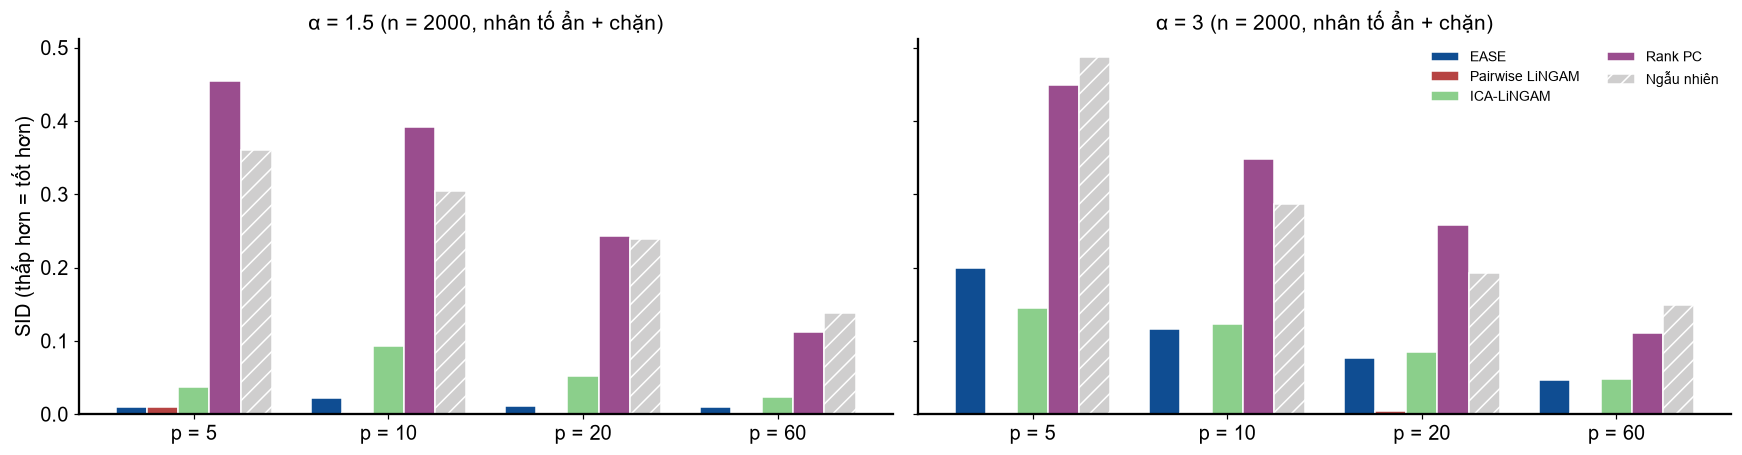

method    EASE  Pairwise LiNGAM  ICA-LiNGAM  Rank PC  Ngẫu nhiên
alpha p                                                         
1.500 5  0.010            0.010       0.038    0.454       0.360
      10 0.022            0.001       0.093    0.392       0.304
      20 0.011            0.000       0.053    0.243       0.239
      60 0.010            0.000       0.023    0.112       0.138
3.000 5  0.200            0.000       0.145    0.449       0.488
      10 0.116            0.002       0.123    0.348       0.287
      20 0.077            0.005       0.084    0.257       0.193
      60 0.047            0.002       0.048    0.111       0.149

In [2]:
sim = pd.concat([read("01_simulation_results"), read("01_simulation_results_p60")], ignore_index=True)
d = sim[(sim.setting == "hidden_censored") & (sim.n == 2000)]
g = d.groupby(["alpha", "p", "method"])["SID"].mean().unstack()[list(CB.METHODS)]
fig, axes = plt.subplots(1, 2, figsize=(16, 4.3), sharey=True)
for ax, a in zip(axes, (1.5, 3.0)):
    gg = g.loc[a]; x = np.arange(len(gg)); w = 0.16
    for i, m in enumerate(CB.METHODS):
        ax.bar(x + (i - 2) * w, gg[m], w, color=METHOD_COLORS[m], label=m, hatch="//" if m == "Ngẫu nhiên" else None, edgecolor="white")
    ax.set_xticks(x, [f"p = {p}" for p in gg.index]); ax.set_title(f"α = {a:g} (n = 2000, nhân tố ẩn + chặn)")
axes[0].set_ylabel("SID (thấp hơn = tốt hơn)"); axes[1].legend(fontsize=9, ncol=2)
U.finalize_figure(fig, "finding_1_simulation", folder=FOLDER); plt.show()
g.round(3)

### Phân tích
- Ở $\alpha = 1{,}5$, EASE gần như hoàn hảo (SID ≤ 0,022 ở mọi $p$); ở $\alpha = 3$ (gần lợi suất cổ phiếu) EASE còn 0,077 với $p = 20$ và **0,047 với $p = 60$** — ngang ICA-LiNGAM (0,084; 0,048),
  kém Pairwise LiNGAM (≤ 0,005), nhưng tốt hơn hẳn Rank PC (0,26; 0,11) và ngẫu nhiên (0,19; 0,15).
- SID chuẩn hoá giảm theo $p$ vì DAG thưa hơn; so với mức ngẫu nhiên, EASE từ 40% ($p = 20$) xuống 32% ($p = 60$) — mở rộng lên 60 mã không làm EASE kém đi.
- Thứ hạng giống mục 5.1 của bài báo. LiNGAM được lợi vì mô phỏng tuyến tính trên toàn phân phối; EASE chỉ dùng $2k$ điểm cực trị.

## Phát hiện 2 — Biên độ ±7% không làm lệch EASE; nhân tố ẩn mới gây hại

**Tính gì:** thay đổi SID trung bình khi thêm từng yếu tố vào SCM tuyến tính: $\Delta_{\text{chặn}} = \overline{\mathrm{SID}}_{\texttt{censored}} - \overline{\mathrm{SID}}_{\texttt{linear}}$,
$\Delta_{\text{ẩn}} = \overline{\mathrm{SID}}_{\texttt{hidden}} - \overline{\mathrm{SID}}_{\texttt{linear}}$. EASE chỉ cần **phiên nào** cực trị và **hạng** của biến hệ quả:
$\hat\Gamma_{jk} = \frac1k\sum_i \hat F_k(X_{ik})\mathbb 1\{X_{ij} > X_{(n-k),j}\}$ — phép chặn giữ nguyên cả hai.

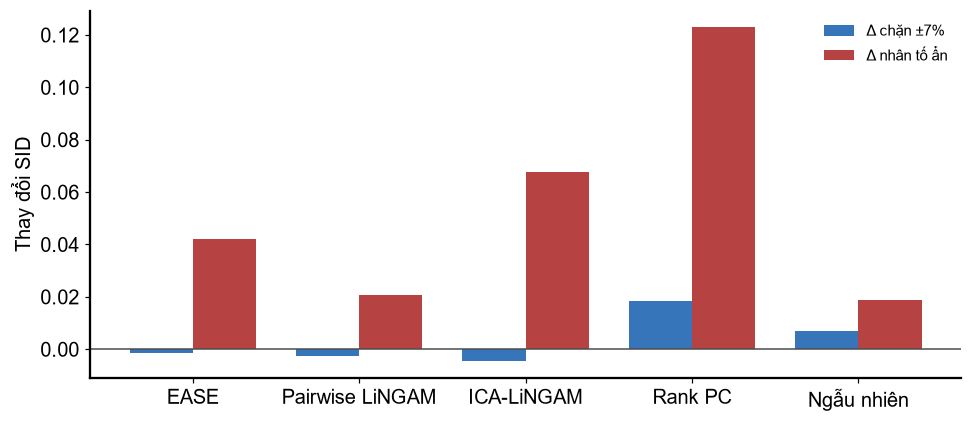

,Δ kiểm duyệt,Δ nhân tố ẩn,Δ cả hai
method,,,
EASE,-0.001,0.042,0.054
Pairwise LiNGAM,-0.003,0.021,0.008
ICA-LiNGAM,-0.005,0.068,0.073
Rank PC,0.018,0.123,0.141
Ngẫu nhiên,0.007,0.019,0.022


In [3]:
eff = read("01_effect_censoring_hidden", index_col=0).loc[list(CB.METHODS)]
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(eff)); w = 0.38
ax.bar(x - w / 2, eff["Δ kiểm duyệt"], w, color=PAL["blue_secondary"], label="Δ chặn ±7%")
ax.bar(x + w / 2, eff["Δ nhân tố ẩn"], w, color=PAL["red_strong"], label="Δ nhân tố ẩn")
ax.axhline(0, color=PAL["gray_dark"], lw=1); ax.set_xticks(x, eff.index); ax.set_ylabel("Thay đổi SID"); ax.legend(fontsize=10)
U.finalize_figure(fig, "finding_2_censoring_vs_hidden", folder=FOLDER); plt.show()
eff.round(3)

### Phân tích
- Chặn hai đuôi không đổi SID của EASE (Δ = −0,001) — khác hẳn ước lượng Hill (EDA phát hiện 4). Nhân tố ẩn tăng SID của mọi phương pháp (EASE +0,042, ICA-LiNGAM +0,068, Rank PC +0,123).
- Với dữ liệu cổ phiếu, rủi ro chính vì vậy là **nhân tố thị trường chung không quan sát được** — trọng tâm của Validation và Calibration.

## Phát hiện 3 — Phụ thuộc đuôi mạnh và mang cấu trúc ngành

**Tính gì:** ma trận $\hat\Psi$ 60 × 60 trên $z$ và trung bình theo khối ngành (ngành nguồn × ngành đích):
$$\hat\Psi_{jk} = \frac{1}{2k}\Big[\sum_{i\in\mathcal U_j}\sigma(\hat F_k(X_{ik})) + \sum_{i\in\mathcal L_j}\sigma(\hat F_k(X_{ik}))\Big],\quad \sigma(v) = |2v - 1|.$$
Độc lập → 1/2; nhân quả trực tiếp → 1.

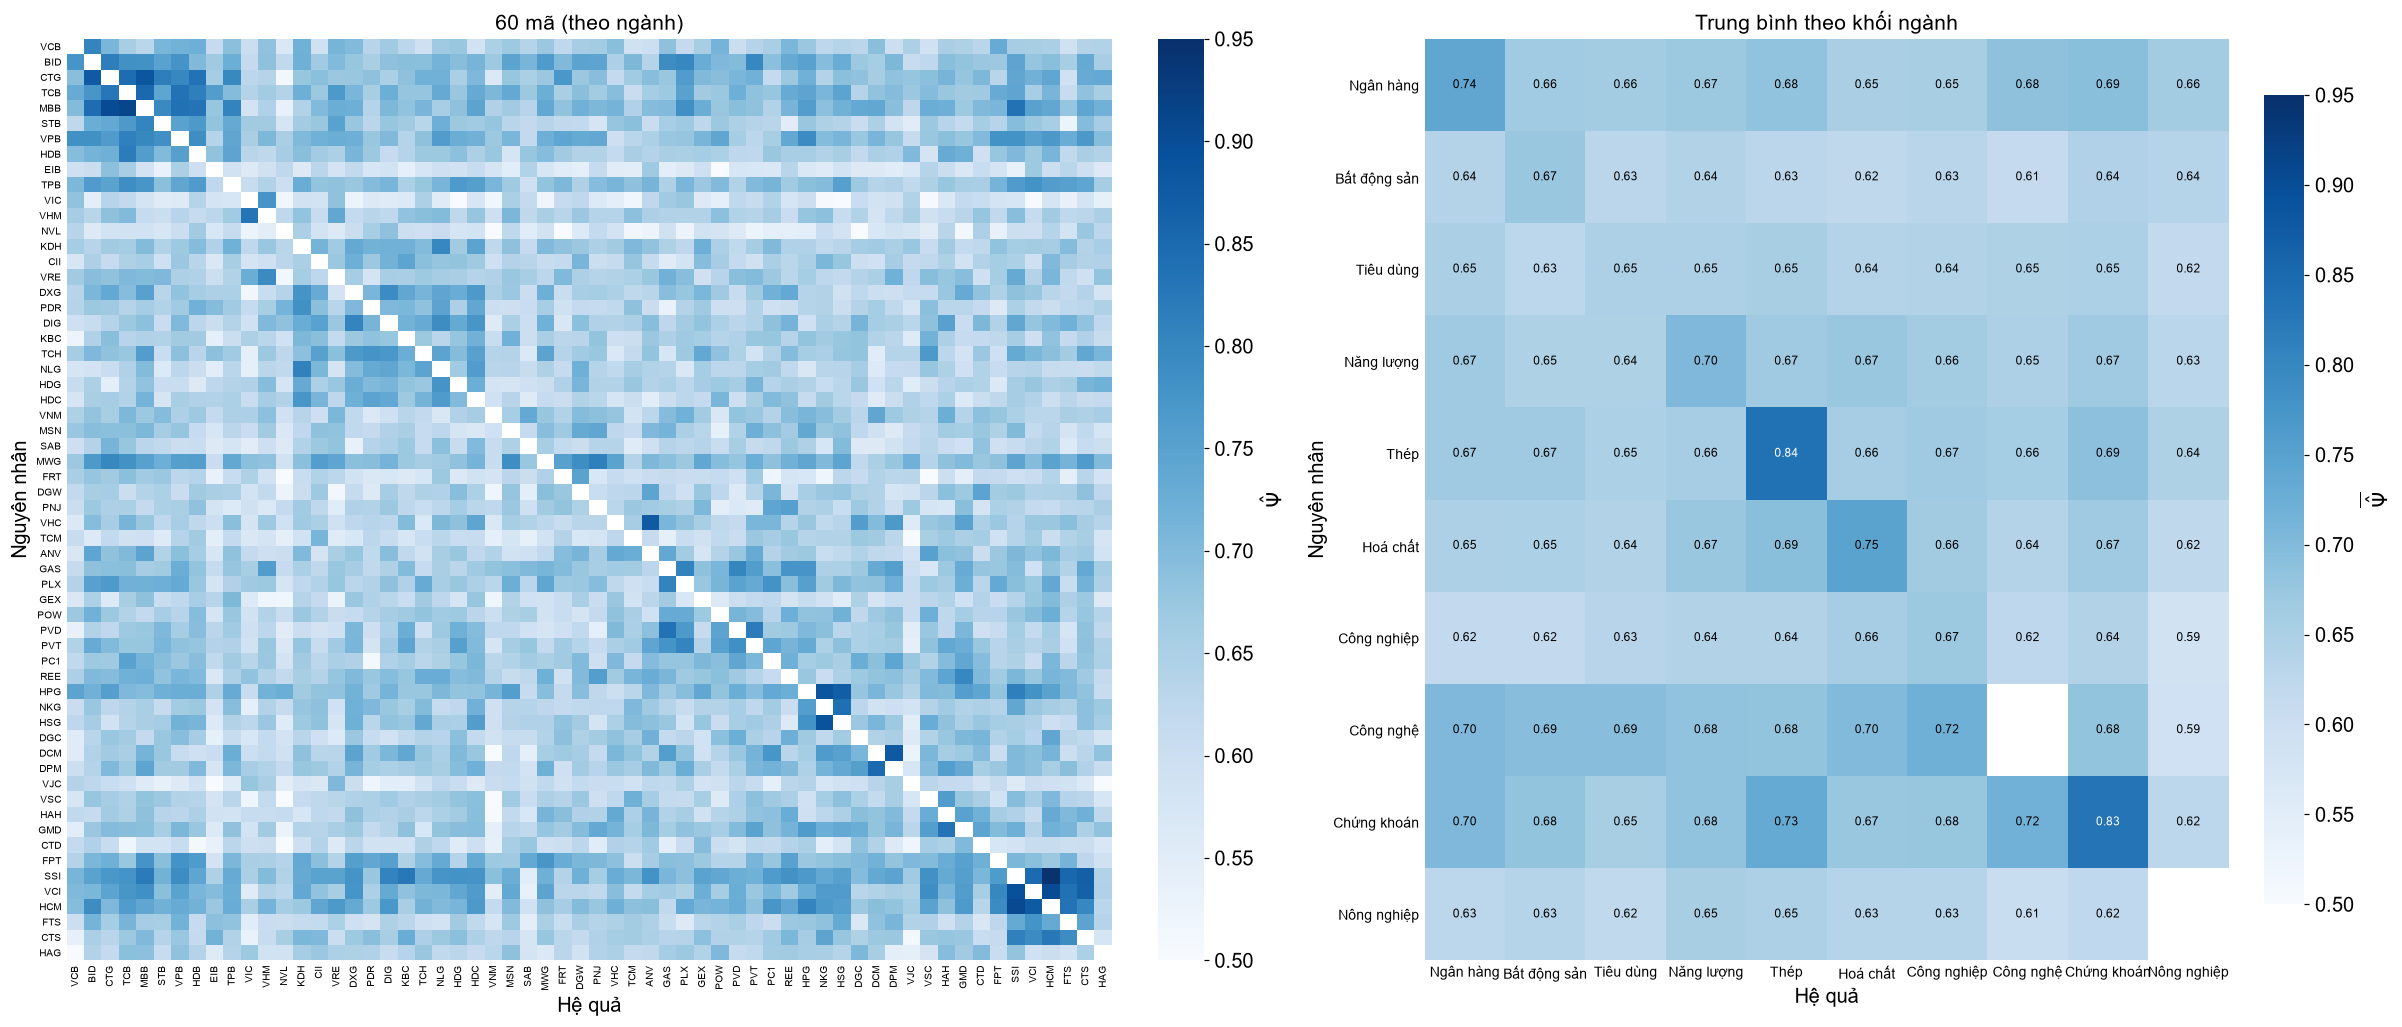

Ψ̂ TB = 0.656; cùng ngành 0.694, khác ngành 0.651
Lớn nhất: {'SSI→HCM': 0.944, 'MBB→TCB': 0.911, 'HCM→SSI': 0.905, 'MBB→CTG': 0.902, 'VCI→HCM': 0.902, 'VCI→SSI': 0.894}


In [4]:
Psi = read("02_psi_matrix", index_col=0).loc[SYMBOLS, SYMBOLS]
blk = sector_blocks(Psi.values)
same = (SEC[:, None] == SEC[None, :]) & OFF
fig, axes = plt.subplots(1, 2, figsize=(22, 9.5), gridspec_kw={"width_ratios": [1.3, 1]})
U.make_heatmap(axes[0], Psi, cmap="Blues", vmin=0.5, vmax=0.95, fmt=None, tick_fontsize=6.5, cbar_label=r"$\hat\Psi$", title=f"{P} mã (theo ngành)")
U.make_heatmap(axes[1], blk, cmap="Blues", vmin=0.5, vmax=0.95, fmt="{:.2f}", annot_fontsize=8, tick_fontsize=9,
               cbar_label=r"$\overline{\hat\Psi}$", title="Trung bình theo khối ngành")
for ax in axes:
    ax.set_xlabel("Hệ quả"); ax.set_ylabel("Nguyên nhân")
U.finalize_figure(fig, "finding_3_sector_structure", folder=FOLDER); plt.show()
print(f"Ψ̂ TB = {Psi.values[OFF].mean():.3f}; cùng ngành {Psi.values[same].mean():.3f}, khác ngành {Psi.values[OFF & ~same].mean():.3f}")
st = Psi.stack().dropna().sort_values(ascending=False); print("Lớn nhất:", {f"{a}→{b}": round(v, 3) for (a, b), v in st.head(6).items()})

### Phân tích
- $\overline{\hat\Psi}$ = 0,66 — mọi cặp đều phụ thuộc ở đuôi; cùng ngành 0,69 > khác ngành 0,65. Đậm nhất là **chứng khoán** (SSI→HCM 0,94, VCI→HCM 0,90), **ngân hàng** (MBB→TCB 0,91, MBB→CTG 0,90)
  và **thép** (HSG→NKG, HPG→NKG 0,89) — các ngành hẹp mà EDA cho thấy gắn kết nhất.
- Đa số cặp có cả hai chiều trong (1/2, 1): theo Bảng 2 của bài báo đây là mẫu hình **nguyên nhân chung**, chưa phải nhân quả trực tiếp.

## Phát hiện 4 — Thứ tự EASE: phi ngân hàng tải thấp trước, ngân hàng sau

**Tính gì:** vị trí trung bình của mỗi mã trong thứ tự EASE qua 500 mẫu bootstrap (bảng `02_bootstrap_rank_freq.csv`), tô màu theo ngành.
EASE (mục 3.1): lặp chọn nút có $M_i = \max_{j\ne i}\hat\Psi_{ji}$ nhỏ nhất — nút **ít bị kéo theo** nhất ở đuôi.

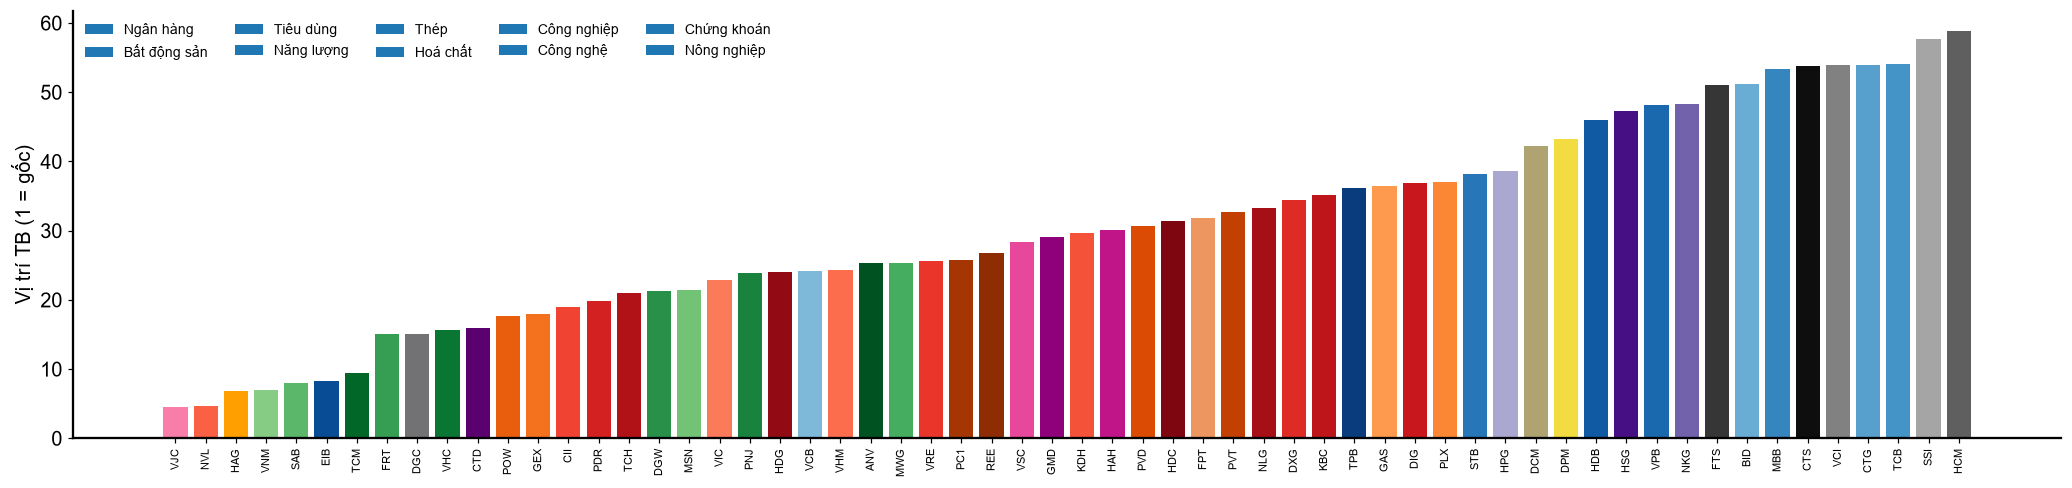

Tần suất làm gốc: {'NVL': 0.3, 'VJC': 0.27, 'VNM': 0.16, 'HAG': 0.09}


In [5]:
rf = read("02_bootstrap_rank_freq", index_col=0); rf.columns = rf.columns.astype(int)
pos = (rf * np.arange(1, P + 1)).sum(axis=1).sort_values()
fig, ax = plt.subplots(figsize=(19, 4.6))
ax.bar(range(P), pos.values, color=[COL[s] for s in pos.index])
ax.set_xticks(range(P), pos.index, rotation=90, fontsize=7.5); ax.set_ylabel("Vị trí TB (1 = gốc)")
for sec in U.SECTORS:
    ax.bar([], [], color=U.SECTOR_COLORS[sec], label=sec)
ax.legend(ncol=5, fontsize=9, loc="upper left")
U.finalize_figure(fig, "finding_4_ease_order", folder=FOLDER); plt.show()
print("Tần suất làm gốc:", rf[1].sort_values(ascending=False).head(4).round(2).to_dict())

### Phân tích
- Gốc phân tán: NVL 30%, VJC 27%, VNM 16%, HAG 9% mẫu bootstrap (với 20 mã NVL làm gốc 82%). Vị trí trung bình thấp nhất: VJC, NVL, HAG, VNM, SAB, EIB — các mã **ít nhạy thị trường**.
- Cuối thứ tự là **chứng khoán** (HCM cuối ở 56% mẫu, SSI, VCI, CTS) và ngân hàng lớn (CTG, TCB, MBB, BID), cùng thép và phân bón — các nhóm "bị kéo theo" nhiều nhất ở đuôi.
- Thứ tự đầy đủ không ổn định (60! hoán vị), chỉ nên đọc ở mức nhóm. Mẫu hình "ít nhạy thị trường trước" được Validation kiểm định trực tiếp.

## Phát hiện 5 — Cú sập lan mạnh hơn cú tăng

**Tính gì:** hệ số đuôi trên $\hat\Gamma_{jk} = \frac1k\sum_{i\in\mathcal U_j}\hat F_k(X_{ik})$ và đuôi dưới $\hat\Gamma^-_{jk} = \frac1k\sum_{i\in\mathcal L_j}(1 - \hat F_k(X_{ik}))$ cho 3.540 cặp.

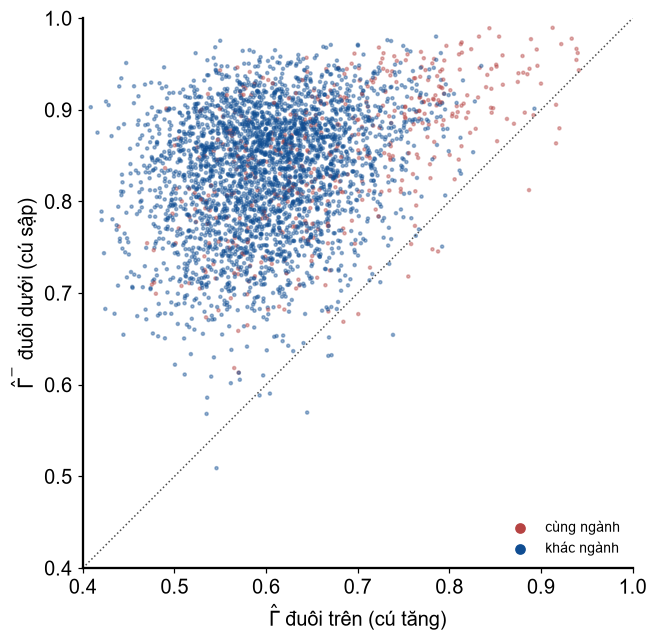

TB: Γ̂ trên = 0.611, Γ̂⁻ dưới = 0.835; số cặp Γ̂⁻ > Γ̂: 3518/3540


In [6]:
Gu = CT.tail_coef_matrix(z, k=K, kind="gamma_upper").values; Gl = CT.tail_coef_matrix(z, k=K, kind="gamma_lower").values
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(Gu[OFF], Gl[OFF], s=4, alpha=0.4, color=np.where(same[OFF], PAL["red_strong"], PAL["blue_main"]))
ax.plot([0.4, 1], [0.4, 1], color=PAL["gray_dark"], ls=":", lw=1); ax.set_xlim(0.4, 1); ax.set_ylim(0.4, 1); ax.set_aspect("equal")
ax.set_xlabel(r"$\hat\Gamma$ đuôi trên (cú tăng)"); ax.set_ylabel(r"$\hat\Gamma^{-}$ đuôi dưới (cú sập)")
ax.scatter([], [], color=PAL["red_strong"], label="cùng ngành"); ax.scatter([], [], color=PAL["blue_main"], label="khác ngành"); ax.legend(fontsize=9)
U.finalize_figure(fig, "finding_5_crash_vs_rally", folder=FOLDER); plt.show()
print(f"TB: Γ̂ trên = {Gu[OFF].mean():.3f}, Γ̂⁻ dưới = {Gl[OFF].mean():.3f}; số cặp Γ̂⁻ > Γ̂: {(Gl[OFF] > Gu[OFF]).sum()}/{int(OFF.sum())}")

### Phân tích
- 3.518/3.540 cặp nằm trên đường chéo: khi một mã sập, mã khác gần như chắc chắn cũng ở vùng thấp nhất; khi tăng mạnh thì không đồng loạt bằng ($\bar\Gamma^-$ 0,835 so với $\bar\Gamma$ 0,611).
- Nhất quán với EDA (phụ thuộc đuôi dưới vượt mức Gaussian ở 1.770/1.770 cặp): mô hình rủi ro danh mục cần xử lý riêng đuôi dưới.

## Phát hiện 6 — EASE và các baseline không đồng thuận ở 60 mã

**Tính gì:** độ đồng thuận cặp $\mathrm{agr}(\pi,\pi') = \binom{p}{2}^{-1}\sum_{i<j}\mathbb 1\{\pi, \pi' \text{ xếp } i, j \text{ cùng chiều}\}$ giữa thứ tự của EASE, Pairwise LiNGAM,
ICA-LiNGAM (đồng thuận 10 seed, cột xáo trộn). Mức nền ngẫu nhiên: trung bình 0,50, phân vị 95% = 0,57.

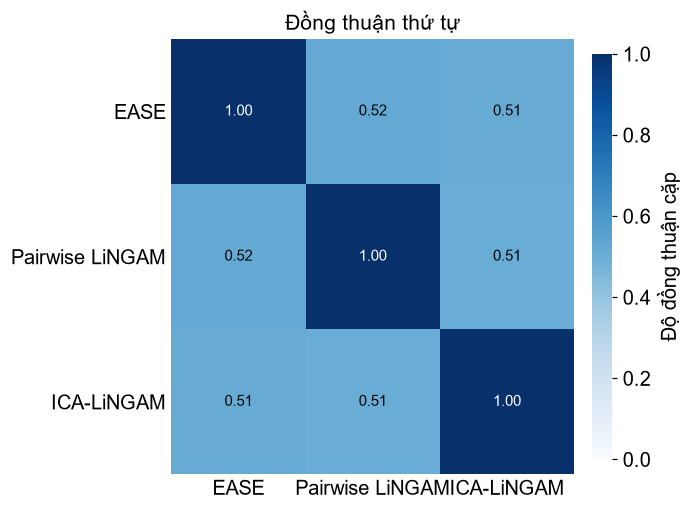

,EASE,Pairwise LiNGAM,ICA-LiNGAM
1,VNM,MBB,DXG
2,VJC,SAB,MWG
3,NVL,SSI,FTS
4,TCM,HCM,PVD
5,HAG,PVD,PLX
6,SAB,GMD,HAG
7,TCH,TCM,VCB
8,PDR,DXG,HAH
9,CTD,VNM,PC1
10,VHC,VHC,VJC


In [7]:
agree = read("02_baseline_agreement", index_col=0)
fig, ax = plt.subplots(figsize=(6.4, 4.8))
U.make_heatmap(ax, agree, cmap="Blues", vmin=0, vmax=1, cbar_label="Độ đồng thuận cặp", title="Đồng thuận thứ tự")
U.finalize_figure(fig, "finding_6_baselines", folder=FOLDER); plt.show()
read("02_baseline_orders", index_col=0).T

### Phân tích
- Đồng thuận 0,51–0,52 — trong dải ngẫu nhiên (phân vị 95% = 0,57); với 20 mã là 0,52–0,65, với 5 mã 0,8–0,9: càng nhiều mã, các phương pháp càng bất đồng.
  Pairwise LiNGAM đặt MBB, SSI, HCM đầu tiên, EASE đặt chính các mã này cuối cùng.
- ICA-LiNGAM với 60 mã không ổn định (đồng thuận giữa các seed 0,50 — như ngẫu nhiên).
- Hai họ phương pháp đo hai thứ khác nhau: LiNGAM dùng phần thân phân phối, EASE dùng đuôi. Cả hai đều bị nhân tố chung chi phối — xem Validation.

## Kết luận Processing
Phụ thuộc đuôi giữa 60 mã mạnh và theo ngành hẹp; EASE cho thứ tự ổn định ở mức nhóm (ít nhạy thị trường trước, chứng khoán/ngân hàng sau) nhưng các phương pháp không đồng thuận.
Câu hỏi then chốt chuyển sang Validation: thứ tự này là nhân quả hay chỉ là dấu vết của nhân tố thị trường?